# Lớp quyết định theo chi phí: so sánh Random Forest và XGBoost

Thay vì chặn giao dịch khi điểm vượt một ngưỡng, notebook này dùng **xác suất đã hiệu chuẩn** và **số tiền giao dịch** để chọn một trong ba hành động **Approve / Review / Block**, bằng cách tối thiểu hóa chi phí kỳ vọng. Chạy cho **cả hai mô hình** để so sánh, kèm phần chạy lặp nhiều seed để kiểm tra độ ổn định.

**Lưu ý:** các chi phí là *kịch bản giả định* để minh họa, không phải số liệu thật. Kết luận chỉ có ý nghĩa trong phạm vi các giả định đã nêu.

## 1. Cấu hình và giả định chi phí

In [1]:
import json, sys, time, warnings
from pathlib import Path

# Tìm thư mục gốc dự án: thư mục cha gần nhất có chứa thư mục "module"
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "module").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss
from xgboost import XGBClassifier

from module.ml_utils import load_data, split_time, split_stratified, get_xy, best_threshold

warnings.filterwarnings("ignore")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

DATA_PATH = PROJECT_ROOT / "dataset" / "creditcard.csv"
SPLIT = "time"                 
SEED = 42
DROP_DUPLICATES = True
OUT_DIR = PROJECT_ROOT / "results"
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ["Random Forest", "XGBoost"]
RUN_MULTI_SEED = True         
N_SEEDS = 5

# ---- GIẢ ĐỊNH CHI PHÍ (cùng đơn vị với cột Amount) -------------------------------------
# Đây là các KỊCH BẢN GIẢ ĐỊNH để minh họa, không phải số liệu thật của ngân hàng.
#   review: chi phí xử lý 1 giao dịch khi điều tra viên xem xét
#   block : thiệt hại khi chặn nhầm 1 giao dịch hợp lệ (mất doanh thu, khách hàng khó chịu)
#   Bỏ sót gian lận: thiệt hại = số tiền (Amount) của giao dịch đó
SCENARIOS = {
    "A (review rẻ)":  {"review": 5,  "block": 30},
    "B (cân bằng)":   {"review": 10, "block": 50},
    "C (review đắt)": {"review": 25, "block": 50},
}
ANALYST_RECALL = 1.0       # xác suất điều tra viên nhận ra gian lận khi review (1.0 = lý tưởng)
CAPACITIES = [None, 100]   # None = không giới hạn; số = tối đa số giao dịch được review trong tập test
                           # (nếu hai dòng cho kết quả giống hệt nhau nghĩa là giới hạn chưa bị chạm -> hạ số này xuống)
K_LIST = [50, 100, 200, 500]

# Cùng cấu hình với các notebook random_forest / xgboost
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample", n_jobs=-1)
XGB_PARAMS = dict(n_estimators=600, learning_rate=0.05, max_depth=6, subsample=0.8,
                  colsample_bytree=0.8, eval_metric="aucpr", early_stopping_rounds=50,
                  tree_method="hist", n_jobs=-1)

## 2. Đọc dữ liệu và chia train / validation / test

In [2]:
df = load_data(DATA_PATH, DROP_DUPLICATES)
features = [c for c in df.columns if c not in ("Time", "Class")]
train, val, test = split_time(df) if SPLIT == "time" else split_stratified(df, SEED)

y_tr, y_va, y_te = train["Class"].values, val["Class"].values, test["Class"].values
amount_te = test["Amount"].values

print(f"train {len(train):,} (fraud {int(y_tr.sum())}) | val {len(val):,} (fraud {int(y_va.sum())}) | "
      f"test {len(test):,} (fraud {int(y_te.sum())})")
assert min(y_tr.sum(), y_va.sum(), y_te.sum()) > 0, "Có tập không chứa mẫu fraud -> đổi SPLIT = 'stratified'"

Đọc 284,807 dòng -> 283,726 dòng sau khi bỏ trùng | fraud = 473 (0.167%)
train 170,235 (fraud 342) | val 56,745 (fraud 57) | test 56,746 (fraud 74)


## 3. Các hàm dùng chung

- `fit_predict`: huấn luyện một mô hình và trả về xác suất thô.
- `calibrate`: hiệu chuẩn xác suất bằng Platt scaling (học trên validation). Cần bước này vì cả hai mô hình đều dùng trọng số lớp nên xác suất thô thường cao hơn tỉ lệ gian lận thực tế.
- `decide`: với mỗi giao dịch chọn hành động có chi phí kỳ vọng thấp nhất (Approve = p × Amount; Block = (1 − p) × chi phí chặn nhầm; Review = chi phí điều tra).
- `evaluate_split`, `rank_at_k`, `reliability`: so sánh chính sách, xếp hạng khi chỉ xem được K cảnh báo, kiểm tra độ tin cậy xác suất.

In [3]:
def fit_predict(name, tr, va, te, seed):
    """Huấn luyện 1 mô hình, trả về (model, p_val_raw, p_test_raw, thông tin huấn luyện)."""
    X_tr, y_tr_ = get_xy(tr, features)
    X_va, y_va_ = get_xy(va, features)
    X_te, _ = get_xy(te, features)
    t0 = time.perf_counter()
    best_it = None
    if name == "Random Forest":
        model = RandomForestClassifier(random_state=seed, **RF_PARAMS).fit(X_tr, y_tr_)
    else:
        pos = y_tr_.mean()
        model = XGBClassifier(random_state=seed, scale_pos_weight=(1 - pos) / pos, **XGB_PARAMS)
        model.fit(X_tr, y_tr_, eval_set=[(X_va, y_va_)], verbose=False)
        best_it = int(model.best_iteration)
    info = {"train_time_s": time.perf_counter() - t0, "best_iteration": best_it}
    return model, model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1], info


def to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)


def calibrate(p_va_raw, y_va_, p_te_raw):
    """Platt scaling: học trên validation, áp dụng cho test (chỉ 2 tham số nên ít bị học vẹt)."""
    platt = LogisticRegression(C=1e6, max_iter=1000).fit(to_logit(p_va_raw), y_va_)
    return platt, platt.predict_proba(to_logit(p_te_raw))[:, 1]


def decide(p, a, review_cost, block_cost, analyst_recall=1.0, capacity=None):
    """Chọn hành động có chi phí kỳ vọng thấp nhất cho từng giao dịch.
    0 = Approve, 1 = Review, 2 = Block. Nếu có capacity thì chỉ review tối đa capacity giao dịch lợi nhất."""
    cost_approve = p * a                                          # nếu là gian lận thì mất Amount
    cost_block = (1 - p) * block_cost                             # nếu hợp lệ thì chịu chi phí chặn nhầm
    cost_review = review_cost + (1 - analyst_recall) * p * a
    decision = np.where(cost_approve <= cost_block, 0, 2)
    benefit = np.minimum(cost_approve, cost_block) - cost_review  # review lợi hơn bao nhiêu so với lựa chọn tốt nhất còn lại
    want = benefit > 0
    if capacity is not None and want.sum() > capacity:
        keep = np.zeros_like(want)
        keep[np.argsort(-benefit)[:capacity]] = True
        want = want & keep
    decision[want] = 1
    return decision


def summarize(model_name, scenario, policy, decision, y, a, review_cost, block_cost, analyst_recall=1.0):
    approve = (decision == 0) * y * a
    review = (decision == 1) * (review_cost + (1 - analyst_recall) * y * a)
    block = (decision == 2) * (1 - y) * block_cost
    total = (approve + review + block).sum()
    base = (y * a).sum()                                          # chi phí nếu không có hệ thống (duyệt hết)
    flagged = decision != 0
    stopped = a[(y == 1) & (decision == 2)].sum() + analyst_recall * a[(y == 1) & (decision == 1)].sum()
    return {
        "model": model_name, "kịch bản": scenario, "chính sách": policy,
        "tổng chi phí": total,
        "giảm so với duyệt hết (%)": 100 * (1 - total / base),
        "giá trị gian lận chặn được (%)": 100 * stopped / base,
        "số review": int((decision == 1).sum()),
        "số block": int((decision == 2).sum()),
        "cảnh báo nhầm": int((flagged & (y == 0)).sum()),
        "precision cảnh báo": float(y[flagged].mean()) if flagged.any() else 0.0,
    }


POLICY_FULL = "3 mức (tối ưu chi phí)"


def evaluate_split(model_name, p_va_raw, p_te_raw, p_te, y_va_, y_te_, a_te):
    """So sánh các chính sách trên một lần chia dữ liệu, cho mọi kịch bản chi phí."""
    thr = best_threshold(y_va_, p_va_raw)                         # ngưỡng F1 chọn trên validation (như các notebook trước)
    decision_bin = np.where(p_te_raw >= thr, 2, 0)
    rows = []
    for sc, cst in SCENARIOS.items():
        rc, bc = cst["review"], cst["block"]
        rows.append(summarize(model_name, sc, "Duyệt hết (không có hệ thống)", np.zeros(len(y_te_), int), y_te_, a_te, rc, bc, ANALYST_RECALL))
        rows.append(summarize(model_name, sc, "Nhị phân (ngưỡng F1)", decision_bin, y_te_, a_te, rc, bc, ANALYST_RECALL))
        for cap in CAPACITIES:
            d = decide(p_te, a_te, rc, bc, ANALYST_RECALL, cap)
            name = POLICY_FULL + ("" if cap is None else f", tối đa {cap} review")
            rows.append(summarize(model_name, sc, name, d, y_te_, a_te, rc, bc, ANALYST_RECALL))
    return rows


def rank_at_k(model_name, p, a, y):
    """Khi chỉ xem được K cảnh báo: xếp theo xác suất hay theo thiệt hại kỳ vọng (xác suất x Amount)?"""
    total_value = a[y == 1].sum()
    out = []
    for label, order in {"Xếp theo xác suất": np.argsort(-p),
                         "Xếp theo thiệt hại kỳ vọng": np.argsort(-(p * a))}.items():
        for k in K_LIST:
            top = order[:k]
            out.append({"model": model_name, "cách xếp": label, "K": k,
                        "precision@K": y[top].mean(),
                        "gian lận bắt được": int(y[top].sum()),
                        "giá trị gian lận bắt được (%)": 100 * a[top][y[top] == 1].sum() / total_value})
    return out


edges = np.array([0, 1e-4, 1e-3, 1e-2, 0.1, 0.5, 1.0000001])
labels = ["<0.01%", "0.01-0.1%", "0.1-1%", "1-10%", "10-50%", ">50%"]


def reliability(p, y):
    """Xác suất dự đoán trung bình so với tỉ lệ gian lận thực tế theo từng khoảng."""
    idx = np.digitize(p, edges) - 1
    rows = []
    for b, lab in enumerate(labels):
        m = idx == b
        rows.append({"khoảng": lab, "n": int(m.sum()),
                     "p dự đoán TB": p[m].mean() if m.any() else np.nan,
                     "tỉ lệ fraud thực": y[m].mean() if m.any() else np.nan})
    return pd.DataFrame(rows)

## 4. Lần chạy chính: huấn luyện, hiệu chuẩn, đánh giá cả hai mô hình

In [4]:
all_rows, calib_rows, rank_rows, train_log, platt_params, reliab = [], [], [], [], {}, {}
probs = {}

for name in MODELS:
    model, p_va_raw, p_te_raw, info = fit_predict(name, train, val, test, SEED)
    platt, p_te = calibrate(p_va_raw, y_va, p_te_raw)
    probs[name] = {"raw": p_te_raw, "cal": p_te}
    platt_params[name] = {"coef": float(platt.coef_[0][0]), "intercept": float(platt.intercept_[0])}
    train_log.append({"model": name, "seed": SEED, "split": SPLIT, **info})
    print(f"{name}: train {info['train_time_s']:.1f}s, best_iteration = {info['best_iteration']}")

    for stage, p in [("Trước hiệu chuẩn", p_te_raw), ("Sau hiệu chuẩn", p_te)]:
        calib_rows.append({"model": name, "giai đoạn": stage,
                           "Brier": brier_score_loss(y_te, p), "Log loss": log_loss(y_te, p),
                           "p dự đoán TB": p.mean(), "tỉ lệ gian lận thực tế": y_te.mean()})
    reliab[name] = {"raw": reliability(p_te_raw, y_te), "cal": reliability(p_te, y_te)}
    all_rows += evaluate_split(name, p_va_raw, p_te_raw, p_te, y_va, y_te, amount_te)
    rank_rows += rank_at_k(name, p_te, amount_te, y_te)

calib_df = pd.DataFrame(calib_rows)
results = pd.DataFrame(all_rows)
rank_df = pd.DataFrame(rank_rows)
print("\n=== Hiệu chuẩn xác suất (test) ===")
display(calib_df.round(5))

Random Forest: train 35.1s, best_iteration = None
XGBoost: train 11.2s, best_iteration = 587

=== Hiệu chuẩn xác suất (test) ===


,model,giai đoạn,Brier,Log loss,p dự đoán TB,tỉ lệ gian lận thực tế
0,Random Forest,Trước hiệu chuẩn,0.00041,0.00611,0.00149,0.0013
1,Random Forest,Sau hiệu chuẩn,0.00041,0.00339,0.00117,0.0013
2,XGBoost,Trước hiệu chuẩn,0.00046,0.00344,0.00122,0.0013
3,XGBoost,Sau hiệu chuẩn,0.00039,0.00263,0.00122,0.0013


## 5. So sánh chính sách

Ba chính sách được so với mốc **duyệt hết** (không có hệ thống): *Nhị phân (ngưỡng F1)* là cách làm cũ, *3 mức (tối ưu chi phí)* là cách mới. Đọc cột **tổng chi phí** (thấp hơn là tốt) và **giảm so với duyệt hết (%)** (cao hơn là tốt).

In [5]:
def compact(metric, digits=1):
    t = results.pivot_table(index=["kịch bản", "chính sách"], columns="model", values=metric, sort=False)
    return t.round(digits)


print("=== Tổng chi phí (thấp hơn là tốt hơn) ===")
display(compact("tổng chi phí", 0))
print("=== Giảm chi phí so với duyệt hết (%) (cao hơn là tốt hơn) ===")
display(compact("giảm so với duyệt hết (%)"))
print("=== Giá trị gian lận chặn được (%) ===")
display(compact("giá trị gian lận chặn được (%)"))
print("=== Chi tiết (số review / block / cảnh báo nhầm / precision cảnh báo) ===")
display(results[["model", "kịch bản", "chính sách", "số review", "số block", "cảnh báo nhầm", "precision cảnh báo"]].round(3))

=== Tổng chi phí (thấp hơn là tốt hơn) ===


model                                                     Random Forest  XGBoost
kịch bản       chính sách                                                       
A (review rẻ)  Duyệt hết (không có hệ thống)                     7728.0   7728.0
               Nhị phân (ngưỡng F1)                              2848.0   3785.0
               3 mức (tối ưu chi phí)                            3055.0   2614.0
               3 mức (tối ưu chi phí), tối đa 100 review         2940.0   2614.0
B (cân bằng)   Duyệt hết (không có hệ thống)                     7728.0   7728.0
               Nhị phân (ngưỡng F1)                              2988.0   3885.0
               3 mức (tối ưu chi phí)                            2972.0   2859.0
               3 mức (tối ưu chi phí), tối đa 100 review         2972.0   2859.0
C (review đắt) Duyệt hết (không có hệ thống)                     7728.0   7728.0
               Nhị phân (ngưỡng F1)                              2988.0   3885.0
               3 mức (tối ưu chi phí)                            2942.0   2884.0
               3 mức (tối ưu chi phí), tối đa 100 review         2942.0   2884.0

=== Giảm chi phí so với duyệt hết (%) (cao hơn là tốt hơn) ===


model                                                     Random Forest  XGBoost
kịch bản       chính sách                                                       
A (review rẻ)  Duyệt hết (không có hệ thống)                        0.0      0.0
               Nhị phân (ngưỡng F1)                                63.1     51.0
               3 mức (tối ưu chi phí)                              60.5     66.2
               3 mức (tối ưu chi phí), tối đa 100 review           62.0     66.2
B (cân bằng)   Duyệt hết (không có hệ thống)                        0.0      0.0
               Nhị phân (ngưỡng F1)                                61.3     49.7
               3 mức (tối ưu chi phí)                              61.5     63.0
               3 mức (tối ưu chi phí), tối đa 100 review           61.5     63.0
C (review đắt) Duyệt hết (không có hệ thống)                        0.0      0.0
               Nhị phân (ngưỡng F1)                                61.3     49.7
               3 mức (tối ưu chi phí)                              61.9     62.7
               3 mức (tối ưu chi phí), tối đa 100 review           61.9     62.7

=== Giá trị gian lận chặn được (%) ===


model                                                     Random Forest  XGBoost
kịch bản       chính sách                                                       
A (review rẻ)  Duyệt hết (không có hệ thống)                        0.0      0.0
               Nhị phân (ngưỡng F1)                                65.9     53.0
               3 mức (tối ưu chi phí)                              68.4     68.8
               3 mức (tối ưu chi phí), tối đa 100 review           68.4     68.8
B (cân bằng)   Duyệt hết (không có hệ thống)                        0.0      0.0
               Nhị phân (ngưỡng F1)                                65.9     53.0
               3 mức (tối ưu chi phí)                              68.4     65.6
               3 mức (tối ưu chi phí), tối đa 100 review           68.4     65.6
C (review đắt) Duyệt hết (không có hệ thống)                        0.0      0.0
               Nhị phân (ngưỡng F1)                                65.9     53.0
               3 mức (tối ưu chi phí)                              68.4     65.6
               3 mức (tối ưu chi phí), tối đa 100 review           68.4     65.6

=== Chi tiết (số review / block / cảnh báo nhầm / precision cảnh báo) ===


,model,kịch bản,chính sách,số review,số block,cảnh báo nhầm,precision cảnh báo
0,Random Forest,A (review rẻ),Duyệt hết (không có hệ thống),0,0,0,0.000
1,Random Forest,A (review rẻ),Nhị phân (ngưỡng F1),0,63,7,0.889
2,Random Forest,A (review rẻ),3 mức (tối ưu chi phí),123,15,111,0.196
3,Random Forest,A (review rẻ),"3 mức (tối ưu chi phí), tối đa 100 review",100,16,89,0.233
4,Random Forest,B (cân bằng),Duyệt hết (không có hệ thống),0,0,0,0.000
5,Random Forest,B (cân bằng),Nhị phân (ngưỡng F1),0,63,7,0.889
6,Random Forest,B (cân bằng),3 mức (tối ưu chi phí),53,14,42,0.373
7,Random Forest,B (cân bằng),"3 mức (tối ưu chi phí), tối đa 100 review",53,14,42,0.373
8,Random Forest,C (review đắt),Duyệt hết (không có hệ thống),0,0,0,0.000
9,Random Forest,C (review đắt),Nhị phân (ngưỡng F1),0,63,7,0.889


## 6. Khi chỉ xem được K cảnh báo

In [6]:
print("=== Khi chỉ xem được K cảnh báo ===")
display(rank_df.round(3))

=== Khi chỉ xem được K cảnh báo ===


,model,cách xếp,K,precision@K,gian lận bắt được,giá trị gian lận bắt được (%)
0,Random Forest,Xếp theo xác suất,50,0.980,49,45.786
1,Random Forest,Xếp theo xác suất,100,0.590,59,69.050
2,Random Forest,Xếp theo xác suất,200,0.315,63,69.432
3,Random Forest,Xếp theo xác suất,500,0.128,64,69.591
4,Random Forest,Xếp theo thiệt hại kỳ vọng,50,0.420,21,68.057
5,Random Forest,Xếp theo thiệt hại kỳ vọng,100,0.230,23,68.283
6,Random Forest,Xếp theo thiệt hại kỳ vọng,200,0.135,27,68.579
7,Random Forest,Xếp theo thiệt hại kỳ vọng,500,0.060,30,76.876
8,XGBoost,Xếp theo xác suất,50,0.960,48,49.037
9,XGBoost,Xếp theo xác suất,100,0.590,59,68.971


## 7. Biểu đồ

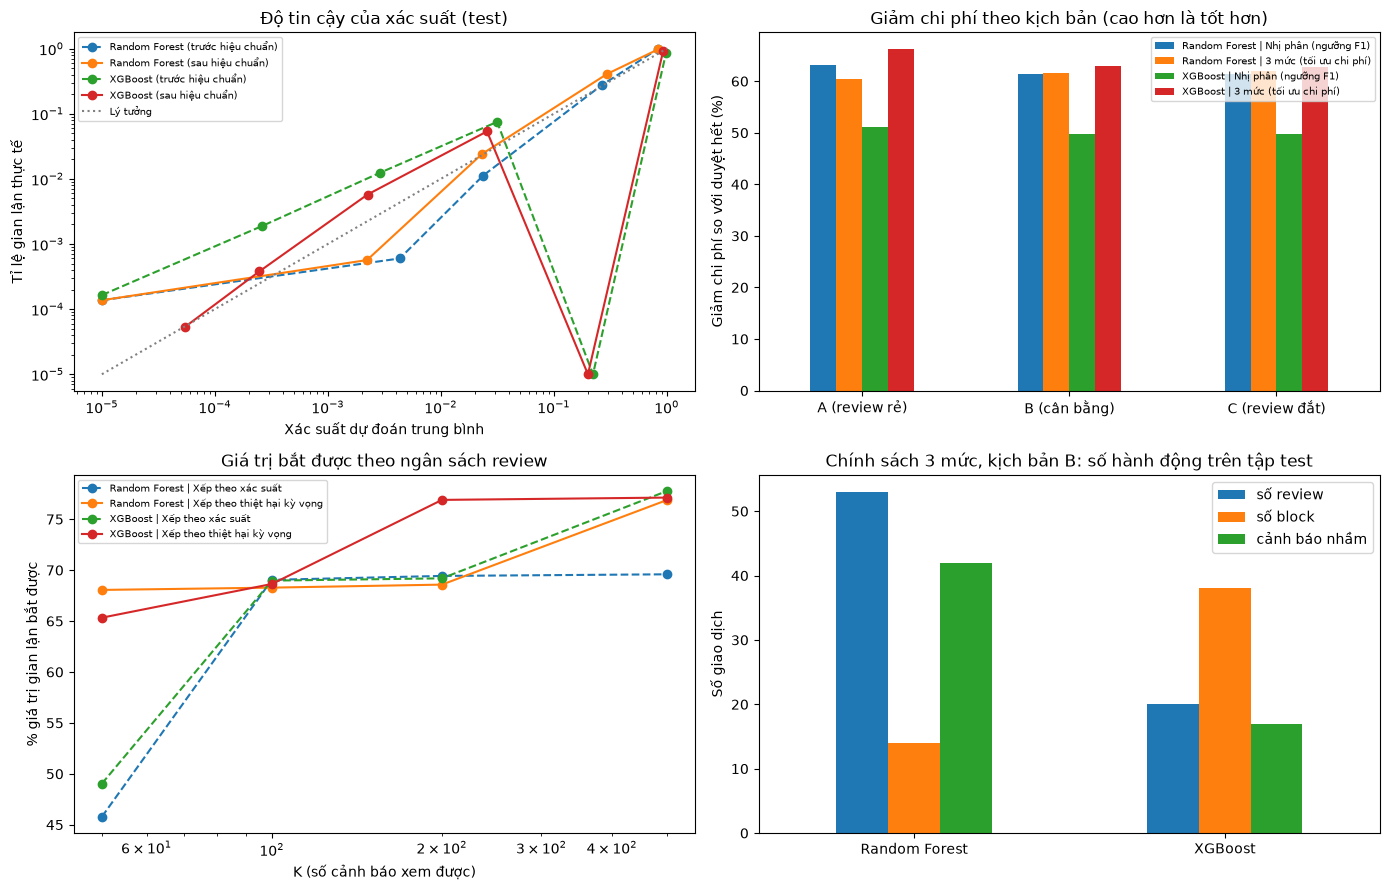

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (1) Độ tin cậy xác suất, mỗi mô hình một đường trước/sau hiệu chuẩn
ax = axes[0, 0]
for name in MODELS:
    for key, ls, lab in [("raw", "--", "trước"), ("cal", "-", "sau")]:
        rel = reliab[name][key]
        m = rel["n"] > 0
        ax.plot(np.maximum(rel.loc[m, "p dự đoán TB"], 1e-5), np.maximum(rel.loc[m, "tỉ lệ fraud thực"], 1e-5),
                "o" + ls, label=f"{name} ({lab} hiệu chuẩn)")
ax.plot([1e-5, 1], [1e-5, 1], ":", c="gray", label="Lý tưởng")
ax.set(xscale="log", yscale="log", xlabel="Xác suất dự đoán trung bình", ylabel="Tỉ lệ gian lận thực tế",
       title="Độ tin cậy của xác suất (test)")
ax.legend(fontsize=7)

# (2) Giảm chi phí so với duyệt hết, theo kịch bản
ax = axes[0, 1]
sel = results[results["chính sách"].isin(["Nhị phân (ngưỡng F1)", POLICY_FULL])]
pv = sel.assign(nhóm=sel["model"] + " | " + sel["chính sách"]).pivot_table(
    index="kịch bản", columns="nhóm", values="giảm so với duyệt hết (%)", sort=False)
pv.plot.bar(ax=ax, rot=0)
ax.set(ylabel="Giảm chi phí so với duyệt hết (%)", xlabel="", title="Giảm chi phí theo kịch bản (cao hơn là tốt hơn)")
ax.legend(fontsize=7)

# (3) Giá trị gian lận bắt được theo K (xếp theo thiệt hại kỳ vọng)
ax = axes[1, 0]
for name in MODELS:
    for label, ls in [("Xếp theo xác suất", "--"), ("Xếp theo thiệt hại kỳ vọng", "-")]:
        s = rank_df[(rank_df["model"] == name) & (rank_df["cách xếp"] == label)]
        ax.plot(s["K"], s["giá trị gian lận bắt được (%)"], "o" + ls, label=f"{name} | {label}")
ax.set(xscale="log", xlabel="K (số cảnh báo xem được)", ylabel="% giá trị gian lận bắt được",
       title="Giá trị bắt được theo ngân sách review")
ax.legend(fontsize=7)

# (4) Số review / block của chính sách 3 mức (kịch bản B)
ax = axes[1, 1]
b = results[(results["chính sách"] == POLICY_FULL) & (results["kịch bản"] == "B (cân bằng)")].set_index("model")
b[["số review", "số block", "cảnh báo nhầm"]].plot.bar(ax=ax, rot=0)
ax.set(xlabel="", ylabel="Số giao dịch", title="Chính sách 3 mức, kịch bản B: số hành động trên tập test")

fig.tight_layout()
fig.savefig(OUT_DIR / "cost_aware_overview.png", dpi=150)
plt.show()

## 8. Độ ổn định: chạy lặp nhiều seed (chia ngẫu nhiên)

In [8]:
ms = pd.DataFrame()
ms_summary = {}
if RUN_MULTI_SEED:
    ms_rows = []
    for s in range(SEED, SEED + N_SEEDS):
        tr, va, te = split_stratified(df, s)
        yv, yt, at = va["Class"].values, te["Class"].values, te["Amount"].values
        for name in MODELS:
            model, pva, pte_raw, info = fit_predict(name, tr, va, te, s)
            _, pte = calibrate(pva, yv, pte_raw)
            for r in evaluate_split(name, pva, pte_raw, pte, yv, yt, at):
                r["seed"] = s
                ms_rows.append(r)
            train_log.append({"model": name, "seed": s, "split": "stratified", **info})
        print(f"xong seed {s}")
    ms = pd.DataFrame(ms_rows)
    ms.to_csv(OUT_DIR / "cost_aware_multi_seed.csv", index=False)

    print("\n=== Giảm chi phí so với duyệt hết (%): trung bình ± độ lệch chuẩn qua các seed ===")
    g = ms.groupby(["kịch bản", "chính sách", "model"], sort=False)["giảm so với duyệt hết (%)"].agg(["mean", "std"]).round(1)
    g["mean ± std"] = g["mean"].astype(str) + " ± " + g["std"].astype(str)
    display(g["mean ± std"].unstack("model"))

    print("\n=== So sánh cặp (cùng seed): XGBoost trừ Random Forest, chính sách 3 mức ===")
    d = ms[ms["chính sách"] == POLICY_FULL].pivot_table(index=["kịch bản", "seed"], columns="model",
                                                        values="giảm so với duyệt hết (%)", sort=False)
    d["XGBoost - RF"] = d["XGBoost"] - d["Random Forest"]
    paired = d.groupby("kịch bản", sort=False)["XGBoost - RF"].agg(
        mean="mean", std="std", so_seed_XGB_hon=lambda x: int((x > 0).sum()))
    display(paired.round(2))
    ms_summary = {"mean_std": g.reset_index().to_dict(orient="records"), "paired": paired.reset_index().to_dict(orient="records")}

xong seed 42
xong seed 43
xong seed 44
xong seed 45
xong seed 46

=== Giảm chi phí so với duyệt hết (%): trung bình ± độ lệch chuẩn qua các seed ===


model                                                    Random Forest     XGBoost
kịch bản       chính sách                                                         
A (review rẻ)  Duyệt hết (không có hệ thống)                 0.0 ± 0.0   0.0 ± 0.0
               Nhị phân (ngưỡng F1)                        62.9 ± 14.2  68.1 ± 7.7
               3 mức (tối ưu chi phí)                      71.1 ± 11.1  74.7 ± 9.2
               3 mức (tối ưu chi phí), tối đa 100 review   75.1 ± 10.8  74.8 ± 9.2
B (cân bằng)   Duyệt hết (không có hệ thống)                 0.0 ± 0.0   0.0 ± 0.0
               Nhị phân (ngưỡng F1)                        61.3 ± 13.9  66.0 ± 8.8
               3 mức (tối ưu chi phí)                      69.8 ± 12.3  73.5 ± 8.3
               3 mức (tối ưu chi phí), tối đa 100 review   69.9 ± 11.5  73.5 ± 8.3
C (review đắt) Duyệt hết (không có hệ thống)                 0.0 ± 0.0   0.0 ± 0.0
               Nhị phân (ngưỡng F1)                        61.3 ± 13.9  66.0 ± 8.8
               3 mức (tối ưu chi phí)                      69.5 ± 11.2  69.3 ± 9.6
               3 mức (tối ưu chi phí), tối đa 100 review   69.5 ± 11.2  69.3 ± 9.6


=== So sánh cặp (cùng seed): XGBoost trừ Random Forest, chính sách 3 mức ===


,mean,std,so_seed_XGB_hon
kịch bản,,,
A (review rẻ),3.62,3.73,4
B (cân bằng),3.68,5.97,3
C (review đắt),-0.27,8.47,3


## 9. Nhật ký huấn luyện

In [9]:
tl = pd.DataFrame(train_log)
print("=== Nhật ký huấn luyện (best_iteration thấp bất thường ở XGBoost = early stopping dừng quá sớm) ===")
display(tl.round(2))

=== Nhật ký huấn luyện (best_iteration thấp bất thường ở XGBoost = early stopping dừng quá sớm) ===


,model,seed,split,train_time_s,best_iteration
0,Random Forest,42,time,35.15,NaN
1,XGBoost,42,time,11.17,587.0
2,Random Forest,42,stratified,34.85,NaN
3,XGBoost,42,stratified,8.82,374.0
4,Random Forest,43,stratified,35.95,NaN
5,XGBoost,43,stratified,6.48,290.0
6,Random Forest,44,stratified,36.85,NaN
7,XGBoost,44,stratified,1.33,8.0
8,Random Forest,45,stratified,35.40,NaN
9,XGBoost,45,stratified,1.60,15.0


## 10. Lưu kết quả

In [11]:
report = {
    "split": SPLIT, "seed": SEED,
    "assumptions": {"scenarios": SCENARIOS, "analyst_recall": ANALYST_RECALL, "capacities": CAPACITIES, "k_list": K_LIST},
    "data": {"train": [len(train), int(y_tr.sum())], "val": [len(val), int(y_va.sum())], "test": [len(test), int(y_te.sum())]},
    "platt": platt_params,
    "calibration": calib_df.to_dict(orient="records"),
    "policies": results.to_dict(orient="records"),
    "ranking_at_k": rank_df.to_dict(orient="records"),
    "train_log": train_log,
    "multi_seed": ms_summary,
}
(OUT_DIR / "cost_aware_metrics.json").write_text(json.dumps(report, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("Đã lưu vào", OUT_DIR)
print(" - cost_aware_metrics.json")
print(" - cost_aware_overview.png")
print(" - cost_aware_multi_seed.csv (nếu RUN_MULTI_SEED = True)")

Đã lưu vào d:\DACN\results
 - cost_aware_metrics.json
 - cost_aware_overview.png
 - cost_aware_multi_seed.csv (nếu RUN_MULTI_SEED = True)
